epoch  1000  total=1.10e-01  pde=1.55e-02  ic=8.17e-04  bc=1.25e-04
epoch  2000  total=1.69e-02  pde=2.93e-03  ic=1.17e-04  bc=2.23e-05
epoch  3000  total=2.45e-03  pde=1.03e-03  ic=1.03e-05  bc=3.86e-06
epoch  4000  total=1.74e-03  pde=6.75e-04  ic=8.68e-06  bc=1.97e-06
epoch  5000  total=1.47e-03  pde=5.22e-04  ic=7.86e-06  bc=1.60e-06
epoch  6000  total=2.23e-03  pde=4.19e-04  ic=1.08e-05  bc=7.26e-06
epoch  7000  total=1.10e-03  pde=3.55e-04  ic=6.24e-06  bc=1.17e-06
epoch  8000  total=1.54e-03  pde=3.02e-04  ic=8.32e-06  bc=4.03e-06
epoch  9000  total=8.73e-04  pde=2.66e-04  ic=5.11e-06  bc=9.65e-07
epoch 10000  total=1.08e-03  pde=2.39e-04  ic=6.02e-06  bc=2.44e-06

relative L2 error: 0.0067 (0.67%)


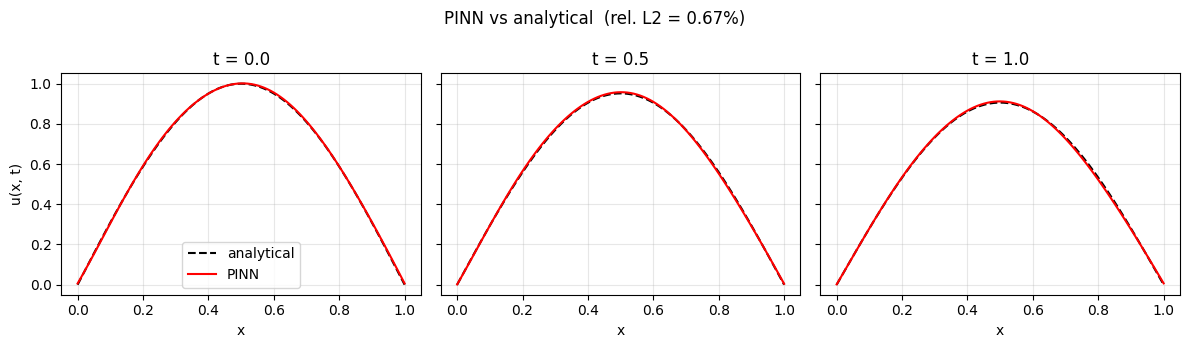

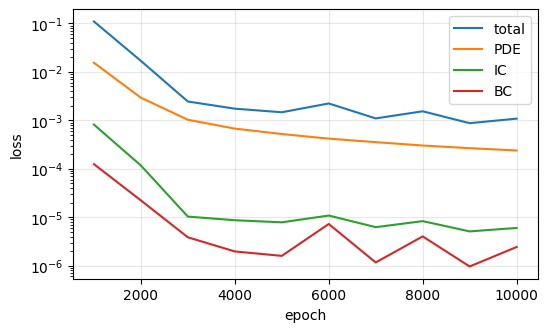

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ---------- config ----------
alpha = 0.01          # diffusion coefficient
T = 1.0               # time domain [0, T]
N_f, N_ic, N_bc = 1000, 200, 200
lam_ic = lam_bc = 100.0   # IC/BC weight vs PDE residual
epochs, lr = 10000, 1e-3
tf.random.set_seed(0); np.random.seed(0)

# ---------- model (same arch as yours) ----------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(1),
])

# ---------- data ----------
X_f  = np.random.rand(N_f, 2) * [1.0, T]                       # interior (x, t)
X_ic = np.column_stack([np.random.rand(N_ic), np.zeros(N_ic)]) # t = 0
u_ic = np.sin(np.pi * X_ic[:, 0:1])                             # u(x,0) = sin(pi x)
t_bc = np.random.rand(N_bc, 1) * T
X_bc = np.vstack([np.column_stack([np.zeros(N_bc), t_bc[:, 0]]),  # x = 0
                  np.column_stack([np.ones(N_bc),  t_bc[:, 0]])])  # x = 1
u_bc = np.zeros((2 * N_bc, 1))                                  # u(0,t) = u(1,t) = 0

X_f  = tf.convert_to_tensor(X_f, dtype=tf.float32)
X_ic = tf.convert_to_tensor(X_ic, dtype=tf.float32)
u_ic = tf.convert_to_tensor(u_ic, dtype=tf.float32)
X_bc = tf.convert_to_tensor(X_bc, dtype=tf.float32)
u_bc = tf.convert_to_tensor(u_bc, dtype=tf.float32)
opt = tf.keras.optimizers.Adam(lr)

@tf.function
def train_step():
    with tf.GradientTape() as tape:                       # param grads
        with tf.GradientTape(persistent=True) as g2:
            with tf.GradientTape(persistent=True) as g1:
                g1.watch(X_f); g2.watch(X_f)
                u = model(X_f)
            u_x = g1.gradient(u, X_f)[:, 0:1]
            u_t = g1.gradient(u, X_f)[:, 1:2]
        u_xx = g2.gradient(u_x, X_f)[:, 0:1]
        f = u_t - alpha * u_xx                            # PDE residual
        loss_f  = tf.reduce_mean(tf.square(f))
        loss_ic = tf.reduce_mean(tf.square(model(X_ic) - u_ic))
        loss_bc = tf.reduce_mean(tf.square(model(X_bc) - u_bc))
        loss = loss_f + lam_ic * loss_ic + lam_bc * loss_bc
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loss_f, loss_ic, loss_bc

# ---------- train ----------
hist = []
for ep in range(1, epochs + 1):
    loss, lf, lic, lbc = train_step()
    if ep % 1000 == 0:
        hist.append((float(loss), float(lf), float(lic), float(lbc)))
        print(f"epoch {ep:5d}  total={loss:.2e}  pde={lf:.2e}  ic={lic:.2e}  bc={lbc:.2e}")

# ---------- validate vs analytical u(x,t) = sin(pi x) * exp(-alpha pi^2 t) ----------
nx, nt = 101, 101
xs = np.linspace(0, 1, nx); ts = np.linspace(0, T, nt)
XX, TT = np.meshgrid(xs, ts)
Xg = np.column_stack([XX.ravel(), TT.ravel()]).astype(np.float32)
u_pred  = model(Xg).numpy().reshape(nt, nx)
u_exact = np.sin(np.pi * XX) * np.exp(-alpha * np.pi**2 * TT)
rel_l2 = np.linalg.norm(u_pred - u_exact) / np.linalg.norm(u_exact)
print(f"\nrelative L2 error: {rel_l2:.4f} ({100*rel_l2:.2f}%)")

# ---------- plots ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, t_snap in zip(axes, [0.0, 0.5, 1.0]):
    j = int(t_snap / T * (nt - 1))
    ax.plot(xs, u_exact[j], 'k--', label='analytical')
    ax.plot(xs, u_pred[j], 'r-', label='PINN')
    ax.set_title(f"t = {t_snap}"); ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("u(x, t)"); axes[0].legend()
fig.suptitle(f"PINN vs analytical  (rel. L2 = {rel_l2:.2%})")
plt.tight_layout(); plt.show()

h = np.array(hist)
plt.figure(figsize=(6, 3.5))
for k, name in enumerate(["total", "PDE", "IC", "BC"]):
    plt.semilogy(np.arange(1, len(h) + 1) * 1000, h[:, k], label=name)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()


### Using Your Fire Perimeter API Key

To securely use your API key, store it in Colab's secrets manager. Click the '🔑' icon in the left panel, add a new secret, and name it `FIRE_PERIMETER_API_KEY` (or any name you prefer). Then, you can access it in your code like this:

In [2]:
# Used to securely store your API key
from google.colab import userdata

# Retrieve your API key from Colab secrets
FIRE_PERIMETER_API_KEY = userdata.get('FIRE_PERIMETER_API_KEY')

# Now you can use FIRE_PERIMETER_API_KEY in your code
# For example, if you have a client library:
# client = FirePerimeterAPIClient(api_key=FIRE_PERIMETER_API_KEY)
# print('API key loaded successfully. You can now use it to make API calls.')

If you can provide more details about the 'Fire Perimeter' API (e.g., specific endpoints, required libraries, or what you want to achieve with it), I can help you generate code to interact with it.

In [3]:
import torch
import torch.nn as nn

# 1. Define the Neural Network
class LevelSetPINN(nn.Module):
    def __init__(self):
        super(LevelSetPINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 32), # inputs: (t, x, y)
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)  # output: u(t, x, y)
        )

    def forward(self, t, x, y):
        inputs = torch.cat([t, x, y], dim=-1)
        return self.net(inputs)

# 2. Compute Physics Residual (e.g., u_t + S * ||grad u|| = 0)
def pde_residual(model, t, x, y, S=1.0):
    u = model(t, x, y)

    # First derivatives via autograd
    grads = torch.autograd.grad(
        u, [t, x, y],
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    # Gradient norm ||grad u||
    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Governing Level Set residual
    residual = u_t + S * grad_norm
    return residual


In [4]:
import torch
import torch.nn as nn
import numpy as np

# --- 1. Define Model Architecture ---
class LevelSetPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(), # Corrected: changed from 2 to 3
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, t, x, y):
        return self.net(torch.cat([t, x, y], dim=-1))

# --- 2. Initial Condition Definition (Circle of radius 0.2 at t=0) ---
def get_signed_distance_circle(x, y, r=0.2):
    return torch.sqrt(x**2 + y**2) - r

# --- 3. Training Point Generation ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LevelSetPINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Sample N points inside the spacetime box: x in [-1,1], y in [-1,1], t in [0, 0.5]
N_pde = 5000
t_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 0.5
x_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0
y_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0

# Initial condition points (t = 0)
N_ic = 1000
t_ic = torch.zeros(N_ic, 1, device=device)
x_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
y_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
u_ic_target = get_signed_distance_circle(x_ic, y_ic)

# --- 4. Optimization Loop ---
for epoch in range(2001):
    optimizer.zero_grad()

    # A. Initial Condition Loss
    u_ic_pred = model(t_ic, x_ic, y_ic)
    loss_ic = torch.mean((u_ic_pred - u_ic_target)**2)

    # B. PDE Residual Loss
    u = model(t_pde, x_pde, y_pde)
    grads = torch.autograd.grad(u, [t_pde, x_pde, y_pde], torch.ones_like(u), create_graph=True, retain_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)
    pde_res = u_t + 1.0 * grad_norm # Constant propagation speed S = 1.0
    loss_pde = torch.mean(pde_res**2)

    # C. Eikonal regularizer (forces ||grad u|| = 1)
    loss_eik = torch.mean((grad_norm - 1.0)**2)

    # Total Loss and update
    loss = 10.0 * loss_ic + 1.0 * loss_pde + 0.1 * loss_eik
    loss.backward(retain_graph=True)
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | IC Loss: {loss_ic.item():.4f} | PDE Loss: {loss_pde.item():.4f}")

Epoch    0 | IC Loss: 0.4655 | PDE Loss: 0.0054
Epoch  500 | IC Loss: 0.0005 | PDE Loss: 0.0103
Epoch 1000 | IC Loss: 0.0002 | PDE Loss: 0.0045
Epoch 1500 | IC Loss: 0.0001 | PDE Loss: 0.0027
Epoch 2000 | IC Loss: 0.0001 | PDE Loss: 0.0021


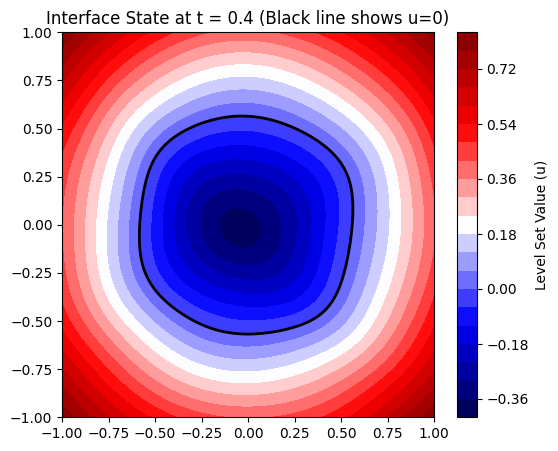

In [5]:
import matplotlib.pyplot as plt

# Generate a grid for plotting at final time t = 0.4
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X, Y = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval = torch.full((grid_res * grid_res, 1), 0.4, device=device)
x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z = model(t_eval, x_eval, y_eval).cpu().numpy().reshape(grid_res, grid_res)

# Interpret boundaries
plt.figure(figsize=(6,5))
# Contour level at 0 is the actual interface position
cp = plt.contourf(X, Y, Z, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
# Highlight the zero-level set boundary explicitly
plt.contour(X, Y, Z, levels=[0], colors='black', linewidths=2)
plt.title("Interface State at t = 0.4 (Black line shows u=0)")
plt.show()


### Visualizing the Initial Condition (t=0)
Let's plot the model's prediction at `t=0` to see how well it captures the initial circle.

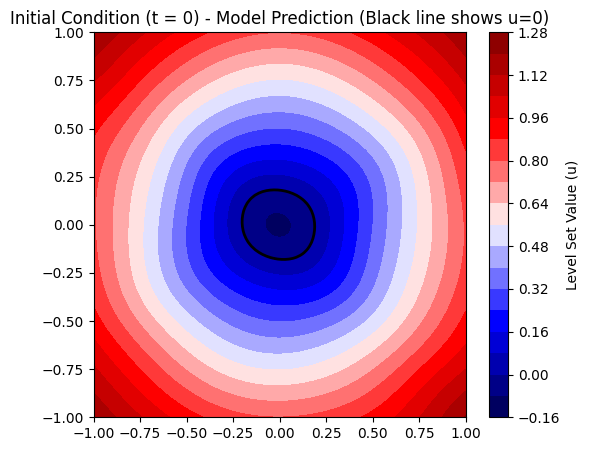

In [6]:
# Generate a grid for plotting at t = 0
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X_0, Y_0 = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval_0 = torch.full((grid_res * grid_res, 1), 0.0, device=device)
x_eval_0 = torch.tensor(X_0.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_0 = torch.tensor(Y_0.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z_0 = model(t_eval_0, x_eval_0, y_eval_0).cpu().numpy().reshape(grid_res, grid_res)

plt.figure(figsize=(6,5))
cp = plt.contourf(X_0, Y_0, Z_0, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
plt.contour(X_0, Y_0, Z_0, levels=[0], colors='black', linewidths=2)
plt.title("Initial Condition (t = 0) - Model Prediction (Black line shows u=0)")
plt.show()

In [7]:
import numpy as np
from skimage import measure
import torch

def export_interface_mesh(model, target_time, resolution=128):
    """Extracts the exact u=0 boundary as a mesh of vertices and faces."""
    # 1. Create a fine grid evaluation bounding box
    lin = np.linspace(-1.0, 1.0, resolution)
    X, Y = np.meshgrid(lin, lin)

    # 2. Format grid for PyTorch inference
    t_eval = torch.full((resolution * resolution, 1), target_time, dtype=torch.float32)
    x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
    y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32)

    with torch.no_grad():
        # Get predictions and reshape back to a 2D image array
        Z = model(t_eval, x_eval, y_eval).numpy().reshape(resolution, resolution)

    # 3. Use Marching Squares/Cubes to isolate the exact 0.0 contour line
    contours = measure.find_contours(Z, level=0.0)

    # 4. Map pixel indexes back to physical coordinate space
    physical_contours = []
    for contour in contours:
        real_x = -1.0 + (contour[:, 1] / (resolution - 1)) * 2.0
        real_y = -1.0 + (contour[:, 0] / (resolution - 1)) * 2.0
        physical_contours.append(np.stack([real_x, real_y], axis=1))

    return physical_contours  # List of coordinates tracking the outer boundary


In [8]:
def check_containment(model, time, x_coord, y_coord):
    """Instantly checks if a coordinate is inside, outside, or on the boundary."""
    t_tensor = torch.tensor([[time]], dtype=torch.float32)
    x_tensor = torch.tensor([[x_coord]], dtype=torch.float32)
    y_tensor = torch.tensor([[y_coord]], dtype=torch.float32)

    with torch.no_grad():
        u_val = model(t_tensor, x_tensor, y_tensor).item()

    if u_val < -1e-3:
        return "INSIDE the boundary structure"
    elif u_val > 1e-3:
        return "OUTSIDE the boundary structure"
    else:
        return "EXACTLY ON the interface edge"


In [9]:
def get_surface_normals(model, t, x, y):
    """Calculates the exact direction the shape's boundary is facing."""
    # Ensure gradients can be tracked
    t.requires_grad_(True)
    x.requires_grad_(True)
    y.requires_grad_(True)

    u = model(t, x, y)

    # Take analytical spatial derivatives via PyTorch Autograd
    grads = torch.autograd.grad(u, [x, y], torch.ones_like(u), create_graph=True)
    u_x, u_y = grads[0], grads[1]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Directional normal vectors pointing outward from the surface
    nx = u_x / grad_norm
    ny = u_y / grad_norm

    return nx.detach(), ny.detach()


In [10]:
def wildfire_pde_residual(model, t, x, y, fuel_spread_rate, wind_x, wind_y):
    u = model(t, x, y)

    # Take derivatives relative to time and space
    grads = torch.autograd.grad(u, [t, x, y], torch.ones_like(u), create_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Wildfire level set equation:
    # Fire moves at its base fuel rate (R) + gets pushed along the wind vector
    advection_term = wind_x * u_x + wind_y * u_y
    pde_residual = u_t + advection_term + (fuel_spread_rate * grad_norm)

    return pde_residual


### Defining Wildfire Parameters: Fuel Spread Rate and Wind

To use the `wildfire_pde_residual` function, we need to specify the `fuel_spread_rate` and the `wind_x` and `wind_y` components. These are crucial for modeling how the fire propagates based on the environment.

In [24]:
# Example values for wildfire parameters
# You would typically derive these from real-world data or scenario assumptions.

# Base rate of fire spread due to fuel (e.g., in units per time step)
# A higher value means faster inherent spread.
fuel_spread_rate = 0.05  # Example: 0.05 units/time

# Wind vector components (e.g., in units per time step)
# Positive values indicate wind in the positive x/y direction.
wind_x = 0.02  # Example: wind pushing slightly in positive x
wind_y = 0.03  # Example: wind pushing slightly in positive y

print(f"Fuel Spread Rate: {fuel_spread_rate}")
print(f"Wind X Component: {wind_x}")
print(f"Wind Y Component: {wind_y}")


Fuel Spread Rate: 0.05
Wind X Component: 0.02
Wind Y Component: 0.03


In [11]:
export_interface_mesh(model, target_time=10)

[]

### Demonstrating `check_containment`
Let's test the `check_containment` function with a specific point at `t=0.4`.

In [12]:
# Example usage of check_containment
test_time = 0.4
test_x_inside = 0.1
test_y_inside = 0.1
test_x_outside = 0.8
test_y_outside = 0.8

status_inside = check_containment(model, test_time, test_x_inside, test_y_inside)
status_outside = check_containment(model, test_time, test_x_outside, test_y_outside)

print(f"Point ({test_x_inside}, {test_y_inside}) at t={test_time}: {status_inside}")
print(f"Point ({test_x_outside}, {test_y_outside}) at t={test_time}: {status_outside}")

Point (0.1, 0.1) at t=0.4: INSIDE the boundary structure
Point (0.8, 0.8) at t=0.4: OUTSIDE the boundary structure


### Demonstrating `get_surface_normals`
Let's visualize the surface normals at a few points along the interface at `t=0.4`.

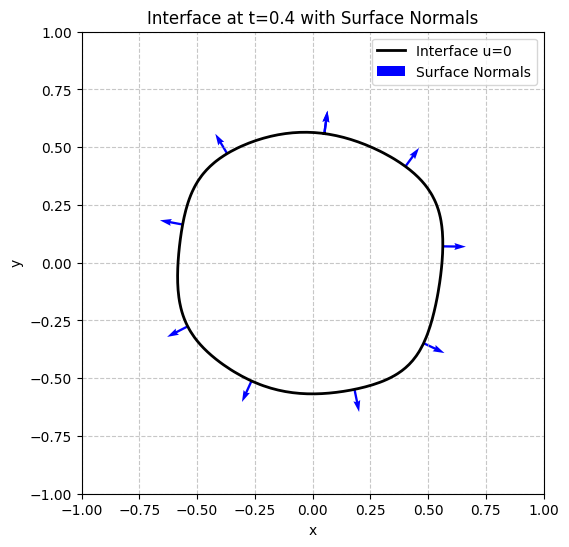

In [13]:
import matplotlib.pyplot as plt

# Get the interface points for visualization of normals
interface_contours = export_interface_mesh(model, target_time=0.4)

plt.figure(figsize=(7,6))

# Plot the interface
if interface_contours:
    for contour in interface_contours:
        plt.plot(contour[:, 0], contour[:, 1], 'k-', linewidth=2, label='Interface u=0')

# Sample points on the interface to plot normals
# We'll take a few points from the first contour if it exists
if interface_contours and len(interface_contours[0]) > 5:
    # Sample a few points for plotting normals
    sample_indices = np.linspace(0, len(interface_contours[0]) - 1, 10, dtype=int)
    sample_points = torch.tensor(interface_contours[0][sample_indices], dtype=torch.float32)

    t_normals = torch.full((sample_points.shape[0], 1), 0.4, device=device, requires_grad=True)
    x_normals = sample_points[:, 0:1].to(device).clone().detach().requires_grad_(True)
    y_normals = sample_points[:, 1:2].to(device).clone().detach().requires_grad_(True)

    nx, ny = get_surface_normals(model, t_normals, x_normals, y_normals)

    # Plot normals
    plt.quiver(x_normals.cpu().detach().numpy(), y_normals.cpu().detach().numpy(),
               nx.cpu().detach().numpy(), ny.cpu().detach().numpy(),
               color='blue', scale=20, width=0.005, label='Surface Normals')

plt.title("Interface at t=0.4 with Surface Normals")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim([-1, 1]); plt.ylim([-1, 1])
plt.legend()
plt.show()

### Animating the Interface Evolution
Let's see how the interface changes over time using `export_interface_mesh`.

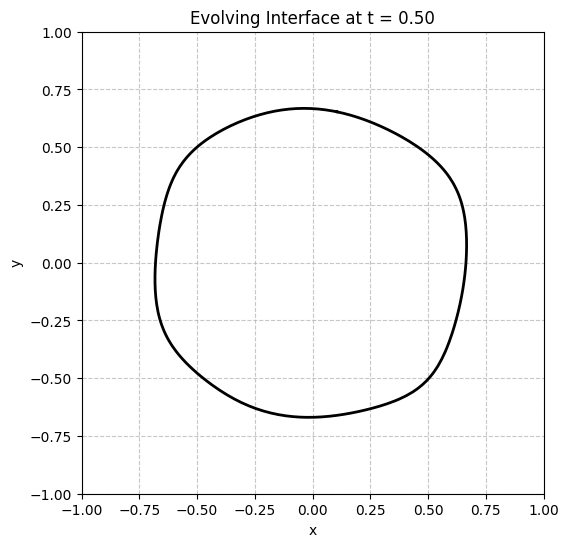

In [14]:
import matplotlib.animation as animation
from IPython.display import HTML

# Define the time steps for the animation
time_steps = np.linspace(0, 0.5, 20) # 20 frames from t=0 to t=0.5

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_title("Evolving Interface")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle='--', alpha=0.7)

line, = ax.plot([], [], 'k-', lw=2)

def animate(i):
    current_time = time_steps[i]
    ax.set_title(f"Evolving Interface at t = {current_time:.2f}")
    contours = export_interface_mesh(model, target_time=current_time)
    if contours:
        # Assuming we are interested in the largest contour if multiple are found
        largest_contour = max(contours, key=len)
        line.set_data(largest_contour[:, 0], largest_contour[:, 1])
    else:
        line.set_data([], []) # Clear data if no contour is found
    return line,

anim = animation.FuncAnimation(fig, animate, frames=len(time_steps), interval=200, blit=True)

# Display the animation
HTML(anim.to_jshtml())

### Getting Terrain Data with `elevation`

To download terrain data, we'll use the `elevation` Python package. This package relies on `GDAL`, so we'll first install `gdal-bin` on the system, then install the `elevation` library itself. Finally, we'll use `elevation.clip` to download a specific region.

In [21]:
# Install GDAL development libraries, which are a dependency for 'elevation'
!sudo apt-get update
!sudo apt-get install -y gdal-bin

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.2 MB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [1,858 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,268 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,544 kB]
Get:13 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [

In [22]:
# Install the elevation Python package
!pip install elevation

In [23]:
import elevation

# Define the bounding box for the desired terrain data (lon_min, lat_min, lon_max, lat_max)
bounds = (-118.70, 34.00, -118.42, 34.14)
output_file = 'srtm.tif'

# Clip the elevation data for the specified bounds and save it to a GeoTIFF file
elevation.clip(bounds=bounds, output=output_file)

print(f"Terrain data clipped and saved to {output_file}")

# You can now further process or visualize 'srtm.tif' using libraries like rasterio or GDAL utilities.

Terrain data clipped and saved to srtm.tif


In [15]:
# Install geemap, which includes earthengine-api as a dependency
!pip install geemap

In [16]:
import ee
import geemap

In [20]:
# Authenticate and initialize Earth Engine
try:
    # Replace 'your-gcp-project-id' with your actual Google Cloud Project ID.
    # You can find this in your Google Cloud Console or Earth Engine console.
    ee.Initialize(project='your-gcp-project-id')
    print('Earth Engine initialized successfully!')
except ee.EEException as e:
    print(f'Failed to initialize Earth Engine: {e}')
    print('Please ensure you have authenticated and provided a valid project ID in ee.Initialize().')

Failed to initialize Earth Engine: Project 'projects/your-gcp-project-id' not found or deleted.
Please ensure you have authenticated and provided a valid project ID in ee.Initialize().


In [18]:
# Run this cell to authenticate your Earth Engine account.
ee.Authenticate()

In [19]:
dataset = ee.ImageCollection('IDAHO_EPSCOR/GRIDMET').filter(
    ee.Filter.date('2018-08-01', '2018-08-15')
)

maximum_temperature = dataset.select('tmmx')

maximum_temperature_vis = {
    'min': 290.0,
    'max': 314.0,
    'palette': ['d8d8d8', '4addff', '5affa3', 'f2ff89', 'ff725c'],
}

m = geemap.Map()
m.set_center(-115.356, 38.686, 5)
m.add_layer(maximum_temperature, maximum_temperature_vis, 'Maximum Temperature')
m

EEException: Earth Engine client library not initialized. See http://goo.gle/ee-auth.